In [36]:
import json
import pandas as pd
import os
# print(os.getcwd())
# print(os.path.abspath(base_path))


pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

In [37]:
# ls

In [38]:
base_path = "../results_mmlu_300"

folders = {

    3: "mmlu_test_eval_service_3_300",
    5: "mmlu_test_eval_service_5_300",
    8: "mmlu_test_eval_service_8_300",
    10: "mmlu_test_eval_service_10_300",
    12: "mmlu_test_eval_service_12_300",
    14: "mmlu_test_eval_service_14_300"

}

In [39]:
data = {}

for k, folder_name in folders.items():

    folder_path = os.path.join(base_path, folder_name)
#     print(folder_path)

    data[k] = []

    for file_name in os.listdir(folder_path):

        if not file_name.endswith(".json"):
            continue

        if "_efficiency" in file_name:
            continue

        file_path = os.path.join(folder_path, file_name)
#         print(file_path)

        with open(file_path, "r") as f:
            rows = json.load(f)
#             print(rows)

        for row in rows:
            row = row.copy()
            row["source_file"] = file_name
            data[k].append(row)

    print(f"K={k}: loaded {len(data[k])} rows")

K=3: loaded 12000 rows
K=5: loaded 16000 rows
K=8: loaded 22000 rows
K=10: loaded 26000 rows
K=12: loaded 30000 rows
K=14: loaded 34000 rows


In [40]:
df_k3 = pd.DataFrame(data[3])
df_k5 = pd.DataFrame(data[5])
df_k8 = pd.DataFrame(data[8])
df_k10 = pd.DataFrame(data[10])
df_k12 = pd.DataFrame(data[12])
df_k14 = pd.DataFrame(data[14])


print("K=3:", df_k3.shape)
print("K=5:", df_k5.shape)
print("K=8:", df_k8.shape)
print("K=10:", df_k10.shape)
print("K=12:", df_k12.shape)
print("K=14:", df_k14.shape)

K=3: (12000, 45)
K=5: (16000, 45)
K=8: (22000, 45)
K=10: (26000, 45)
K=12: (30000, 45)
K=14: (34000, 45)


In [41]:
# df_k3.columns.tolist()# df_k3.columns

## combined df

In [42]:
df_combined = pd.concat([df_k3, df_k5, df_k8, df_k10, df_k12, df_k14], ignore_index=True)

print(df_combined.shape)
print(df_combined["total_service_count"].value_counts())

(140000, 45)
14    34000
12    30000
10    26000
8     22000
5     16000
3     12000
Name: total_service_count, dtype: int64


In [43]:
K = 14  # largest pool

# 1. Accuracy and median latency at K=14 for each router
acc = df_combined[df_combined["total_service_count"] == K].groupby("model_name")["is_correct"].mean() * 100
lat = df_combined[df_combined["total_service_count"] == K].groupby("model_name")["latency_ms"].median()
fam = df_combined.groupby("model_name")["routing_method"].first()

t = pd.DataFrame({"latency": lat, "accuracy": acc, "family": fam}).sort_values("latency")
t["label"] = [m.split("/")[-1] for m in t.index]

display(t[["label", "family", "latency", "accuracy"]].round(2))   # <- shows the table

# 2. Plot (rest of your code unchanged)
...

,label,family,latency,accuracy
model_name,,,,
sentence-transformers/all-MiniLM-L6-v2,all-MiniLM-L6-v2,bi-encoder,4.80,66.82
colbert-ir/colbertv2.0,colbertv2.0,colbert,9.21,50.47
LiquidAI/LFM2-ColBERT-350M,LFM2-ColBERT-350M,colbert,13.80,69.59
BAAI/bge-large-en-v1.5,bge-large-en-v1.5,bi-encoder,13.99,69.00
lightonai/Reason-ModernColBERT,Reason-ModernColBERT,colbert,15.57,72.35
mixedbread-ai/mxbai-colbert-large-v1,mxbai-colbert-large-v1,colbert,15.69,56.94
Qwen/Qwen3-Embedding-0.6B,Qwen3-Embedding-0.6B,bi-encoder,27.66,62.18
Qwen/Qwen3-Embedding-4B,Qwen3-Embedding-4B,bi-encoder,35.40,54.76
Qwen/Qwen3-Embedding-8B,Qwen3-Embedding-8B,bi-encoder,35.75,63.06


Ellipsis

In [44]:
acc_table = pd.pivot_table(
    df_combined,
    values="is_correct",
    index=["routing_method", "model_name"],
    columns="total_service_count",
    aggfunc="mean",
) * 100

acc_table = acc_table.round(2)
acc_table.columns.name = "K"
acc_table

# print(acc_table.to_latex(float_format="%.2f"))

K                                                         3      5      8   \
routing_method model_name                                                    
bi-encoder     BAAI/bge-large-en-v1.5                  91.67  89.00  82.82   
               Qwen/Qwen3-Embedding-0.6B               83.00  78.75  71.27   
               Qwen/Qwen3-Embedding-4B                 89.67  75.12  65.64   
               Qwen/Qwen3-Embedding-8B                 88.67  83.00  74.55   
               sentence-transformers/all-MiniLM-L6-v2  88.83  80.50  74.73   
colbert        LiquidAI/LFM2-ColBERT-350M              93.33  85.12  81.45   
               colbert-ir/colbertv2.0                  77.00  66.12  58.36   
               lightonai/Reason-ModernColBERT          91.67  89.88  83.55   
               mixedbread-ai/mxbai-colbert-large-v1    80.50  71.12  67.91   
cross-encoder  BAAI/bge-reranker-v2-m3                 92.83  84.50  72.00   
               Qwen/Qwen3-Reranker-0.6B                94.17  87.50  82.36   
               Qwen/Qwen3-Reranker-4B                  97.50  95.12  87.64   
               Qwen/Qwen3-Reranker-8B                  87.50  93.00  90.09   
               mixedbread-ai/mxbai-rerank-large-v2     94.67  90.00  84.09   
llm            llama3.1:8b                             74.00  69.25  73.09   
               phi4:14b                                70.00  79.62  86.09   
               qwen2.5:14b                             96.67  93.38  84.27   
               qwen2.5:32b                             88.33  86.75  84.82   
               qwen2.5:7b                              75.00  64.75  63.00   
               qwen3:32b                               96.17  93.62  92.36   

K                                                         10     12     14  
routing_method model_name                                                   
bi-encoder     BAAI/bge-large-en-v1.5                  80.77  71.27  69.00  
               Qwen/Qwen3-Embedding-0.6B               69.77  64.67  62.18  
               Qwen/Qwen3-Embedding-4B                 64.46  57.53  54.76  
               Qwen/Qwen3-Embedding-8B                 71.69  66.13  63.06  
               sentence-transformers/all-MiniLM-L6-v2  73.62  69.53  66.82  
colbert        LiquidAI/LFM2-ColBERT-350M              77.38  71.60  69.59  
               colbert-ir/colbertv2.0                  57.46  54.67  50.47  
               lightonai/Reason-ModernColBERT          80.46  74.87  72.35  
               mixedbread-ai/mxbai-colbert-large-v1    64.00  60.33  56.94  
cross-encoder  BAAI/bge-reranker-v2-m3                 70.23  65.00  59.71  
               Qwen/Qwen3-Reranker-0.6B                78.62  73.53  70.35  
               Qwen/Qwen3-Reranker-4B                  87.15  82.73  81.35  
               Qwen/Qwen3-Reranker-8B                  89.85  84.80  82.47  
               mixedbread-ai/mxbai-rerank-large-v2     82.54  76.73  74.71  
llm            llama3.1:8b                             71.23  69.00  66.18  
               phi4:14b                                85.46  82.40  79.47  
               qwen2.5:14b                             85.15  78.80  78.41  
               qwen2.5:32b                             85.92  82.07  80.18  
               qwen2.5:7b                              57.38  58.13  54.35  
               qwen3:32b                               91.85  87.73  86.94

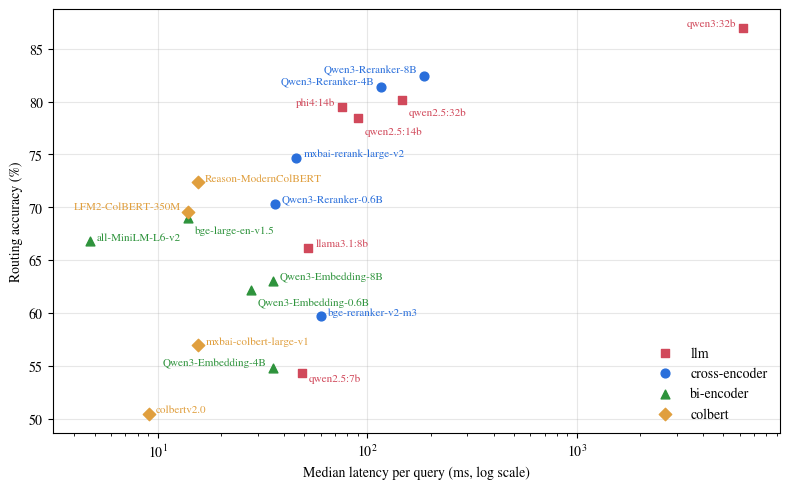

In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Font: STIX (Times-style serif, comes with matplotlib)
plt.rcParams.update({
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
    "pdf.fonttype": 42,  
})

K = 14 

# 1. Accuracy at K=14 and median latency for each router
acc = df_combined[df_combined["total_service_count"] == K].groupby("model_name")["is_correct"].mean() * 100
lat = df_combined.groupby("model_name")["latency_ms"].median()
fam = df_combined.groupby("model_name")["routing_method"].first()

t = pd.DataFrame({"latency": lat, "accuracy": acc, "family": fam}).sort_values("latency")
t["label"] = [m.split("/")[-1] for m in t.index]   # drop "BAAI/", "Qwen/" etc.

# 2. Plot
colors  = {"llm": "#d1495b", "cross-encoder": "#2a6fdb", "bi-encoder": "#2e933c", "colbert": "#e09f3e"}
markers = {"llm": "s", "cross-encoder": "o", "bi-encoder": "^", "colbert": "D"}

offsets = {
    "qwen3:32b":(-5,  4, "right"),
    "LFM2-ColBERT-350M":    (-5,  4, "right"),
    "bge-large-en-v1.5":    ( 5, -9, "left"),
    "phi4:14b":             (-5,  4, "right"),
    "qwen2.5:14b":          ( 5, -9, "left"),
    "Qwen3-Reranker-4B":    (-5,  4, "right"),
    "qwen2.5:32b":          ( 5, -9, "left"),
    "Qwen3-Reranker-8B":    (-5,  4, "right"),
    "Qwen3-Embedding-0.6B": ( 5, -9, "left"),
    "Qwen3-Embedding-4B":   (-5,  4, "right"),
    "qwen2.5:7b":           ( 5, -4, "left"),
}

fig, ax = plt.subplots(figsize=(8, 5))

for fam_name in colors:
    s = t[t["family"] == fam_name]
    ax.scatter(s["latency"], s["accuracy"], c=colors[fam_name], marker=markers[fam_name],
               s=40, zorder=3, label=fam_name)

for m, r in t.iterrows():
    dx, dy, align = offsets.get(r["label"], (5, 3, "left"))
    ax.annotate(r["label"], (r["latency"], r["accuracy"]), xytext=(dx, dy),
                textcoords="offset points", ha=align, va="center",
                fontsize=8, color=colors[r["family"]])

ax.set_xscale("log")
ax.set_xlim(t["latency"].min() / 1.5, t["latency"].max() * 1.5)
ax.set_xlabel("Median latency per query (ms, log scale)")
ax.set_ylabel("Routing accuracy (%)")
ax.grid(alpha=0.3)
ax.legend(loc="lower right", frameon=False)

plt.tight_layout()
plt.savefig("fig_latency_accuracy_k14.pdf")            
plt.savefig("fig_latency_accuracy_k14.png", dpi=300)  
plt.show()

In [61]:
# Only the unrelated queries (correct answer = general)
ood = df_combined[df_combined["expected_service"] == "general"]

ood_table = pd.pivot_table(
    ood,
    values="is_correct",
    index=["routing_method", "model_name"],
    columns="total_service_count",
    aggfunc="mean",
) * 100

ood_table = ood_table.round(2)
ood_table.columns.name = "K"
ood_table

K                                                          3       5       8   \
routing_method model_name                                                       
bi-encoder     BAAI/bge-large-en-v1.5                   94.00   92.67   89.33   
               Qwen/Qwen3-Embedding-0.6B                86.00   89.67   89.33   
               Qwen/Qwen3-Embedding-4B                  99.00   83.67   94.00   
               Qwen/Qwen3-Embedding-8B                  93.67   87.67   90.67   
               sentence-transformers/all-MiniLM-L6-v2   91.00   93.00   90.00   
colbert        LiquidAI/LFM2-ColBERT-350M               94.00   88.33   85.00   
               colbert-ir/colbertv2.0                   93.33   89.67   89.33   
               lightonai/Reason-ModernColBERT           89.00   92.33   93.67   
               mixedbread-ai/mxbai-colbert-large-v1     87.00   72.67   84.00   
cross-encoder  BAAI/bge-reranker-v2-m3                  95.00   95.00   94.67   
               Qwen/Qwen3-Reranker-0.6B                 96.33   93.00   91.33   
               Qwen/Qwen3-Reranker-4B                   96.67   93.00   81.67   
               Qwen/Qwen3-Reranker-8B                   77.67   86.67   88.67   
               mixedbread-ai/mxbai-rerank-large-v2      95.67   95.67   94.33   
llm            llama3.1:8b                              52.67   31.00   32.00   
               phi4:14b                                 97.00   99.33   97.67   
               qwen2.5:14b                              99.33   91.67   65.00   
               qwen2.5:32b                             100.00  100.00  100.00   
               qwen2.5:7b                              100.00  100.00   99.33   
               qwen3:32b                                99.33   92.67   93.33   

K                                                         10     12     14  
routing_method model_name                                                   
bi-encoder     BAAI/bge-large-en-v1.5                  89.33  73.33  72.00  
               Qwen/Qwen3-Embedding-0.6B               95.00  89.00  92.67  
               Qwen/Qwen3-Embedding-4B                 98.33  98.00  96.67  
               Qwen/Qwen3-Embedding-8B                 99.00  98.00  98.33  
               sentence-transformers/all-MiniLM-L6-v2  89.67  88.00  87.67  
colbert        LiquidAI/LFM2-ColBERT-350M              84.67  83.00  83.33  
               colbert-ir/colbertv2.0                  87.00  85.00  86.00  
               lightonai/Reason-ModernColBERT          94.33  93.67  93.67  
               mixedbread-ai/mxbai-colbert-large-v1    84.33  86.33  83.67  
cross-encoder  BAAI/bge-reranker-v2-m3                 93.67  93.33  94.00  
               Qwen/Qwen3-Reranker-0.6B                88.00  85.00  83.33  
               Qwen/Qwen3-Reranker-4B                  83.00  81.00  80.67  
               Qwen/Qwen3-Reranker-8B                  90.33  87.33  87.67  
               mixedbread-ai/mxbai-rerank-large-v2     94.33  95.33  95.00  
llm            llama3.1:8b                             28.00  29.67  26.00  
               phi4:14b                                98.00  95.00  99.33  
               qwen2.5:14b                             71.00  61.33  63.67  
               qwen2.5:32b                             98.33  95.00  95.67  
               qwen2.5:7b                              99.33  99.00  99.00  
               qwen3:32b                               95.00  90.00  91.00

### inspect a model

In [20]:
MODEL = "qwen2.5:14b"

In [21]:
d3 = df_k3[df_k3["model_name"] == MODEL].copy()

d5 = df_k5[df_k5["model_name"] == MODEL].copy()

d8 = df_k8[df_k8["model_name"] == MODEL].copy()

d10 = df_k10[df_k10["model_name"] == MODEL].copy()
d12 = df_k12[df_k12["model_name"] == MODEL].copy()
d14 = df_k14[df_k14["model_name"] == MODEL].copy()


print("K=3", d3.shape)
print("K=5", d5.shape)
print("K=8", d8.shape)

print("K=10", d10.shape)
print("K=12", d12.shape)
print("K=14", d14.shape)


K=3 (600, 45)
K=5 (800, 45)
K=8 (1100, 45)
K=10 (1300, 45)
K=12 (1500, 45)
K=14 (1700, 45)


In [22]:
def expand_scores_and_zscores(df):
    """
    Expand the nested `scores` and `zscores` dict columns
    into normal dataframe columns.
    """

    scores_df = (
        pd.json_normalize(df["scores"])
        .add_suffix("_score")
    )

    zscores_df = (
        pd.json_normalize(df["zscores"])
        .add_suffix("_zscore")
    )

    df_expanded = pd.concat(
        [
            df.reset_index(drop=True),
            scores_df.reset_index(drop=True),
            zscores_df.reset_index(drop=True),
        ],
        axis=1,
    )

    return df_expanded

In [23]:
d3 = expand_scores_and_zscores(d3)
d5 = expand_scores_and_zscores(d5)
d8 = expand_scores_and_zscores(d8)
d10 = expand_scores_and_zscores(d10)
d12 = expand_scores_and_zscores(d12)
d14 = expand_scores_and_zscores(d14)

In [30]:
d3["latency_ms"].mean()

74.0153581427395

In [24]:
# d3.columns.to_list()

In [25]:
def recall_summary(df):

    specialist_df = df[
        df["expected_service"] != "general"
    ]

    general_df = df[
        df["expected_service"] == "general"
    ]

    accuracy = df["is_correct"].mean()

    specialist_recall = (
        specialist_df["predicted_label"]
        == specialist_df["expected_service"]
    ).mean()

    general_recall = (
        general_df["predicted_label"]
        == "general"
    ).mean()

    print(
        f"Accuracy: {accuracy:.4f}"
    )

    print(
        f"Specialist Recall: "
        f"{specialist_recall:.4f}"
    )

    print(
        f"General Recall: "
        f"{general_recall:.4f}"
    )


In [26]:
recall_summary(d3)
recall_summary(d5)
recall_summary(d8)
recall_summary(d10)
recall_summary(d12)
recall_summary(d14)


Accuracy: 0.9667
Specialist Recall: 0.9400
General Recall: 0.9933
Accuracy: 0.9337
Specialist Recall: 0.9440
General Recall: 0.9167
Accuracy: 0.8427
Specialist Recall: 0.9150
General Recall: 0.6500
Accuracy: 0.8515
Specialist Recall: 0.8940
General Recall: 0.7100
Accuracy: 0.7880
Specialist Recall: 0.8317
General Recall: 0.6133
Accuracy: 0.7841
Specialist Recall: 0.8157
General Recall: 0.6367


In [27]:
recall_summary(d3)

Accuracy: 0.9667
Specialist Recall: 0.9400
General Recall: 0.9933


In [56]:
cm_k3 = pd.crosstab(
    d3["expected_service"],
    d3["predicted_label"]
)

cm_k3

predicted_label,abstract_algebra,anatomy,astronomy,general
expected_service,,,,
abstract_algebra,100,0,0,0
anatomy,0,79,0,21
astronomy,1,0,96,3
general,12,0,1,87


In [59]:
error_k3 = d3[ (d3["expected_service"] == "general") & (d3["predicted_label"] == "abstract_algebra")]

In [60]:
error_k3[
    [
        "query",
        "expected_service",
        "predicted_label",

#         "abstract_algebra_zscore",
#         "anatomy_zscore",
#         "astronomy_zscore",

#         "top_zscore",
#         "second_top_zscore",
#         "zscore_margin",

#         "std_score",

        "abstract_algebra_score",
        "anatomy_score",
        "astronomy_score",
    ]
]

,query,expected_service,predicted_label,abstract_algebra_score,anatomy_score,astronomy_score
302,what is my card's apr rate,general,abstract_algebra,0.375085,0.261893,0.336628
305,Where are cards delivered to?,general,abstract_algebra,0.376542,0.312142,0.296283
306,Can I change my information?,general,abstract_algebra,0.365122,0.276881,0.309708
308,Can I add money with Apple Pay?,general,abstract_algebra,0.318832,0.232156,0.244091
311,"If I feel someone has my card information, can I get a new card?",general,abstract_algebra,0.318907,0.240769,0.257824
315,Why did I have to pay extra because I paid with card?,general,abstract_algebra,0.339233,0.247010,0.288934
322,What type of ATMs accept this card?,general,abstract_algebra,0.340776,0.258323,0.283335
323,The balance on my account wasn't updated after I made a depost.,general,abstract_algebra,0.351609,0.250895,0.314534
333,"Can you help me with a weird charge? It's a pound charge that never goes away from the statement view on the app I'm using. It's not described as anything but ""Pending"", and that status has never changed during the last two days.",general,abstract_algebra,0.419431,0.323504,0.366770
335,How can I fix a problem where contactless isn't working?,general,abstract_algebra,0.330076,0.242827,0.275585


# K5

In [34]:
recall_summary(d5)

Accuracy: 0.9600
Specialist Recall: 0.9700
General Recall: 0.9100


In [35]:
cm_k5 = pd.crosstab(
    d5["expected_service"],
    d5["predicted_label"]
)
cm_k5

predicted_label,abstract_algebra,anatomy,astronomy,business_ethics,college_computer_science,general
expected_service,,,,,,
abstract_algebra,99,0,0,0,0,1
anatomy,0,100,0,0,0,0
astronomy,1,1,97,0,0,1
business_ethics,1,0,0,95,1,3
college_computer_science,5,0,0,0,94,1
general,0,2,3,1,3,91


In [36]:
# error_k5 = d5[ (d5["expected_service"] == "general") & (d5["predicted_label"] == "anatomy")]

In [37]:
# error_k5[
#     [
#         "query",
#         "expected_service",
#         "predicted_label",

#         "abstract_algebra_zscore",
#         "anatomy_zscore",
#         "astronomy_zscore",
#         "business_ethics_zscore",
#         "college_computer_science_zscore",

# #         "top_zscore",
# #         "second_top_zscore",
#         "zscore_margin",

#         "std_score",

#         "abstract_algebra_score",
#         "anatomy_score",
#         "astronomy_score",
#         "business_ethics_score",
#         "college_computer_science_score",
#     ]
# ]

# K8

In [38]:
recall_summary(d8)

Accuracy: 0.8878
Specialist Recall: 0.8950
General Recall: 0.8300


In [39]:
cm_k8 = pd.crosstab(
    d8["expected_service"],
    d8["predicted_label"]
)

cm_k8

predicted_label,abstract_algebra,anatomy,astronomy,business_ethics,college_computer_science,general,high_school_chemistry,high_school_geography,jurisprudence
expected_service,,,,,,,,,
abstract_algebra,99,0,0,0,0,1,0,0,0
anatomy,0,98,0,0,0,0,2,0,0
astronomy,0,0,97,0,0,3,0,0,0
business_ethics,0,0,0,85,1,5,0,1,8
college_computer_science,6,0,0,0,93,1,0,0,0
general,0,2,3,1,4,83,0,0,7
high_school_chemistry,2,2,1,0,0,0,95,0,0
high_school_geography,1,1,4,3,0,34,0,52,5
jurisprudence,0,0,0,0,0,3,0,0,97


In [40]:
# error_k8 = d8[ (d8["expected_service"] == "general") & (d8["predicted_label"] == "anatomy")]

In [41]:
# error_k8[
#     [
#         "query",
#         "expected_service",
#         "predicted_label",

#         "abstract_algebra_zscore",
#         "anatomy_zscore",
#         "astronomy_zscore",
#         "business_ethics_zscore",
#         "college_computer_science_zscore",
#         "high_school_chemistry_zscore",
#         "high_school_geography_zscore",
#         "jurisprudence_zscore",

# #         "top_zscore",
# #         "second_top_zscore",
#         "zscore_margin",

#         "std_score",

#         "abstract_algebra_score",
#         "anatomy_score",
#         "astronomy_score",
#         "business_ethics_score",
#         "college_computer_science_score",
#         "high_school_chemistry_score",
#         "high_school_geography_score",
#         "jurisprudence_score",
#     ]
# ]

# K10

In [42]:
recall_summary(d10)

Accuracy: 0.8782
Specialist Recall: 0.8790
General Recall: 0.8700


In [43]:
cm_k10 = pd.crosstab(
    d10["expected_service"],
    d10["predicted_label"]
)

cm_k10

predicted_label,abstract_algebra,anatomy,astronomy,business_ethics,college_computer_science,formal_logic,general,high_school_chemistry,high_school_geography,jurisprudence,world_religions
expected_service,,,,,,,,,,,
abstract_algebra,94,0,0,0,0,6,0,0,0,0,0
anatomy,0,99,0,0,0,0,0,1,0,0,0
astronomy,0,0,97,0,0,1,2,0,0,0,0
business_ethics,0,0,0,83,1,1,4,0,0,7,4
college_computer_science,5,0,0,0,90,4,1,0,0,0,0
formal_logic,0,0,0,0,0,96,1,0,0,1,2
general,0,1,2,1,2,0,87,0,0,6,1
high_school_chemistry,0,2,0,0,0,0,0,98,0,0,0
high_school_geography,1,0,2,4,0,1,32,0,45,4,11


In [46]:
error_k10 = d10[ (d10["expected_service"] == "high_school_geography") & (d10["predicted_label"] == "general")]

In [47]:
error_k10[
    [
        "query",
        "expected_service",
        "predicted_label",

#         "abstract_algebra_zscore",
#         "anatomy_zscore",
#         "astronomy_zscore",
#         "business_ethics_zscore",
#         "college_computer_science_zscore",
#         "formal_logic_zscore",
#         "high_school_chemistry_zscore",
#         "high_school_geography_zscore",
#         "jurisprudence_zscore",
#         "world_religions_zscore",

#         "top_zscore",
#         "second_top_zscore",
#         "zscore_margin",

#         "std_score",

        "abstract_algebra_score",
        "anatomy_score",
        "astronomy_score",
        "business_ethics_score",
        "college_computer_science_score",
        "formal_logic_score",
        "high_school_chemistry_score",
        "high_school_geography_score",
        "jurisprudence_score",
        "world_religions_score",
    ]
]

,query,expected_service,predicted_label,abstract_algebra_score,anatomy_score,astronomy_score,business_ethics_score,college_computer_science_score,formal_logic_score,high_school_chemistry_score,high_school_geography_score,jurisprudence_score,world_religions_score
701,"Olives, grapes, and chickpeas are staple crops of which type of farming?",high_school_geography,general,-13.6875,-12.1250,-12.6875,-13.7500,-13.3750,-14.3125,-12.7500,-11.6250,-13.5625,-12.8125
702,The majority of Kurds are found in which country?,high_school_geography,general,-14.0625,-13.1875,-13.6250,-14.1875,-13.8750,-14.3125,-13.7500,-12.1250,-14.0000,-12.6875
707,A map that presents a single class of statistics is called a,high_school_geography,general,-10.2500,-11.2500,-10.0625,-12.0625,-10.6250,-11.0000,-11.8750,-10.3750,-11.5000,-12.3125
715,A chief factor that contributed to the Second Agricultural Revolution was,high_school_geography,general,-11.6250,-12.6875,-11.8750,-13.1250,-12.8125,-13.4375,-12.9375,-12.6875,-12.2500,-11.9375
720,Which of the following statements is NOT part of Gunnar Myrdal's theory of cumulative causation?,high_school_geography,general,-11.6875,-12.9375,-11.8125,-12.5625,-11.3750,-11.5000,-12.6250,-11.6875,-10.0000,-11.9375
721,"Part of the boundary between the United States and Mexico is the Rio Grande, an example of",high_school_geography,general,-12.3125,-11.0000,-10.4375,-13.4375,-12.7500,-13.3750,-12.0625,-11.0000,-10.2500,-11.3125
726,The purpose for the creation of NATO was to,high_school_geography,general,-12.6875,-12.7500,-12.2500,-13.3750,-12.6250,-13.2500,-13.4375,-13.3750,-12.5000,-12.1875
729,Which factor in the last quarter century greatly destabilized Eastern Europe and led to ethnic conflict?,high_school_geography,general,-12.0000,-12.1875,-12.3750,-12.4375,-13.0625,-14.0000,-12.9375,-12.0625,-11.8750,-11.5625
730,Opponents of genetically modified organisms (GMOs) in food are afraid that the GMOs,high_school_geography,general,-13.0625,-11.2500,-11.8750,-12.0000,-12.8750,-12.5000,-12.0625,-13.3750,-11.4375,-12.1250
731,What family do most European languages belong to?,high_school_geography,general,-13.0000,-12.6250,-12.8750,-14.1250,-13.1875,-12.5625,-13.3125,-11.6875,-13.1250,-11.9375
